# Person 2 — Benchmark review and local-hosting costs

Assignment 1 contribution: **100 completed benchmark evaluations, response-level scores, six workload cases and 90 itemized local-hosting estimates**. Assignment 2 RAG evidence is in `slm/person2_rag_colab.ipynb`.

This analysis reads saved results and computes estimates; it never downloads weights, runs inference or provisions cloud resources. The original executed Colab benchmark notebook and raw CSV remain separate and unchanged. Review method is **AI-assisted inspection of each actual continuation; student signoff pending**, not independent human grading. See the hash-bound review audit and per-response notes. All scores use the team's 3+2+2+2+1 rubric, floored at 1/10. Negative outputs were not repaired or replaced.

In [1]:
from pathlib import Path
import json, csv, statistics, hashlib, math
import pandas as pd
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'a7/benchmark_contract.py').exists())
import sys
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from a7.person2.review_benchmarks import reviewed_rows
from a7.person2.local_costs import build_tables
pd.set_option('display.max_rows', 110)
pd.set_option('display.max_colwidth', 110)
raw = pd.read_csv(ROOT/'a7/results/person2_nf4_colab/person2_benchmark.csv', keep_default_na=False)
reviewed = pd.read_csv(ROOT/'a7/results/person2_benchmark.csv', keep_default_na=False)
assert len(raw) == len(reviewed) == 100
assert raw.status.eq('ok').all() and reviewed.status.eq('ok').all()
expected_review = pd.DataFrame(reviewed_rows())
pd.testing.assert_frame_equal(reviewed.astype(str), expected_review.astype(str))
environment = json.loads((ROOT/'a7/results/person2_nf4_colab/person2_benchmark.environment.json').read_text())
print(json.dumps(environment['condition'], indent=2))
print('100/100 successful; raw responses preserved; all rubric scores validated.')

{
  "models": [
    "facebook/opt-125m",
    "Qwen/Qwen2-0.5B-Instruct",
    "HuggingFaceTB/SmolLM2-1.7B-Instruct",
    "mistralai/Mistral-7B-Instruct-v0.3"
  ],
  "gpu": "Tesla T4",
  "gpu_bytes": 15637086208,
  "python": "3.13.16",
  "device": "cuda",
  "quantization": "nf4",
  "compute_dtype": "float32",
  "attention": "eager",
  "max_new_tokens": 220,
  "do_sample": false,
  "batch_size": 1,
  "packages": {
    "torch": "2.11.0+cu130",
    "transformers": "4.57.6",
    "accelerate": "1.15.0",
    "bitsandbytes": "0.50.2"
  },
  "source_sha256": {
    "a7/benchmark_runner.py": "c5d9b8d4158585ad150c20e5cfc263a2531f6537c49bc7e120557bd8224c5be7",
    "a7/benchmark_contract.py": "87d109d66ecc713e7692e98f1da5dda1e354e18324ead006304aa6159ab1df4d",
    "a7/model_registry.csv": "9b3f587cce095d1b9dea7cba5971fa51c652ce30a5603326ec95e4c455f2f62a",
    "a7/prompts.csv": "0c856ed9b6c483c6b44b3b5805227cc6e09222e0b3998c1f86fce7a694bde68a"
  }
}
100/100 successful; raw responses preserved; all rubr

## Measurement and scoring boundaries

All four Person 2 models used the same Tesla T4, NF4 weights, FP32 compute/nonquantized layers, eager attention, batch 1, greedy decoding and 220-token cap. Latency measures `generate()` with GPU synchronization; loading/download and tokenizer preparation are excluded. The full time to all output tokens is not time to first token or HTTP response time. Different response lengths affect both latency and tokens/sec; a larger model's longer answer cannot be compared by raw latency alone.

A wrong but well-formed single label receives format/clarity credit, not semantic accuracy. Case and one trailing period are normalized as in the shared reviewer; extra prose loses adherence credit. Priority judgments use the locked team references (HIGH/LOW/HIGH/URGENT/MEDIUM), which are rubric choices rather than universal facts. JSON is assessed as emitted: trailing punctuation, invalid enums, incomplete fields and placeholder text are documented. Appropriate suggested plan actions are allowed; invented personal facts, changed constraints or false completion claims are penalized. No keyword-matching heuristic is presented as a completed content review.

In [2]:
model_summary = reviewed.groupby('model_id', sort=False).agg(
    runs=('prompt_id', 'size'), mean_quality=('self_evaluation_score_1_to_10', 'mean'),
    median_latency_seconds=('latency_seconds', 'median'),
    median_tokens_per_second=('tokens_per_second', 'median'),
    mean_output_tokens=('output_tokens', 'mean'))
model_summary['at_220_token_cap'] = reviewed.groupby('model_id').output_tokens.apply(lambda s: int(s.eq(220).sum()))
display(model_summary.round(4))
display(reviewed.pivot_table(index='model_id', columns='prompt_type', values='self_evaluation_score_1_to_10', aggfunc='mean').round(2))
model_summary.to_csv(ROOT/'a7/results/person2_model_summary.csv')

,runs,mean_quality,median_latency_seconds,median_tokens_per_second,mean_output_tokens,at_220_token_cap
model_id,,,,,,
facebook/opt-125m,25,1.08,3.1447,69.9590,220.00,25
Qwen/Qwen2-0.5B-Instruct,25,5.20,1.4941,22.4989,45.48,1
HuggingFaceTB/SmolLM2-1.7B-Instruct,25,4.96,0.8802,20.5394,44.92,1
mistralai/Mistral-7B-Instruct-v0.3,25,8.12,4.1807,9.5678,76.68,1


prompt_type,action_planning,classification,priority_prediction,structured_extraction,summarization
model_id,,,,,
HuggingFaceTB/SmolLM2-1.7B-Instruct,3.6,4.8,5.2,5.8,5.4
Qwen/Qwen2-0.5B-Instruct,4.4,4.6,5.2,5.4,6.4
facebook/opt-125m,1.4,1.0,1.0,1.0,1.0
mistralai/Mistral-7B-Instruct-v0.3,8.2,10.0,5.8,7.4,9.2


In [3]:
# Required 100-row benchmark table, with the exact shared inputs and individual review notes.
display(reviewed[['model_id','model_category','tokens_per_second','latency_seconds',
                  'prompt_type','prompt','self_evaluation_score_1_to_10','review_notes']])

,model_id,model_category,tokens_per_second,latency_seconds,prompt_type,prompt,self_evaluation_score_1_to_10,review_notes
0,facebook/opt-125m,Ultra-light (<0.2B),50.6852,4.3405,structured_extraction,"Guests arrive tomorrow. Clean the kitchen, buy snacks, and fix the leaking bathroom tap.",1,AI-assisted response inspection; student signoff pending. Repetitive continuation/request echo rather than...
1,facebook/opt-125m,Ultra-light (<0.2B),67.9368,3.2383,structured_extraction,"This week I need to book the dentist, replace smoke-detector batteries, return a library book by Friday, a...",1,AI-assisted response inspection; student signoff pending. Repetitive continuation/request echo rather than...
2,facebook/opt-125m,Ultra-light (<0.2B),71.1546,3.0919,structured_extraction,"Before Saturday, vacuum the living room and pick up the birthday cake. The loose stair rail also needs rep...",1,AI-assisted response inspection; student signoff pending. Repetitive continuation/request echo rather than...
3,facebook/opt-125m,Ultra-light (<0.2B),68.1088,3.2301,structured_extraction,"Please remind us to pay the electricity bill tonight, schedule the dog's vet visit, and get laundry deterg...",1,AI-assisted response inspection; student signoff pending. Repetitive continuation/request echo rather than...
4,facebook/opt-125m,Ultra-light (<0.2B),69.9623,3.1445,structured_extraction,The refrigerator is making noise. Also organize the hall closet and mail the tax documents before Monday.,1,AI-assisted response inspection; student signoff pending. Repetitive continuation/request echo rather than...
5,facebook/opt-125m,Ultra-light (<0.2B),66.6292,3.3019,classification,Buy milk and rice after work.,1,AI-assisted response inspection; student signoff pending. Repetitive continuation/request echo rather than...
6,facebook/opt-125m,Ultra-light (<0.2B),68.6660,3.2039,classification,Call the plumber about the dripping kitchen pipe.,1,AI-assisted response inspection; student signoff pending. Repetitive continuation/request echo rather than...
7,facebook/opt-125m,Ultra-light (<0.2B),71.4518,3.0790,classification,Schedule a yearly dental cleaning.,1,AI-assisted response inspection; student signoff pending. Repetitive continuation/request echo rather than...
8,facebook/opt-125m,Ultra-light (<0.2B),68.7441,3.2003,classification,Submit the apartment renewal form by Friday.,1,AI-assisted response inspection; student signoff pending. Repetitive continuation/request echo rather than...
9,facebook/opt-125m,Ultra-light (<0.2B),70.5225,3.1196,classification,Sweep the porch and empty the recycling.,1,AI-assisted response inspection; student signoff pending. Repetitive continuation/request echo rather than...


## Findings from these four models

Mistral has the highest mean reviewed score (8.12/10), especially classification, summaries and useful planning content. It still produces invalid array/key JSON in four of five planning outputs, truncates one extraction, invents an overdue title and sometimes misses the team's priority references; quality is not equivalent to production readiness.

Larger is not consistently better: Qwen (0.494B, 5.20/10) slightly exceeds SmolLM (1.7B, 4.96/10). Qwen often omits extraction fields and chooses wrong labels; SmolLM frequently copies schema placeholders. Both need response/schema validation and fallback before task creation. OPT's 69.96 median tokens/sec produces mostly repetition at the generation cap, with only 1.08/10 mean quality; speed alone is not useful task completion.

For this four-model slice, Mistral offers the best measured quality but only about 9.57 tokens/sec; Qwen is the faster, lower-quality alternative at about 22.50 tokens/sec. There is no evidence that either meets a production quality gate on every prompt. The large category leads **this subset**, not the whole 15-model assignment; other owners' results and hardware conditions must be integrated before a full-team category winner is declared.

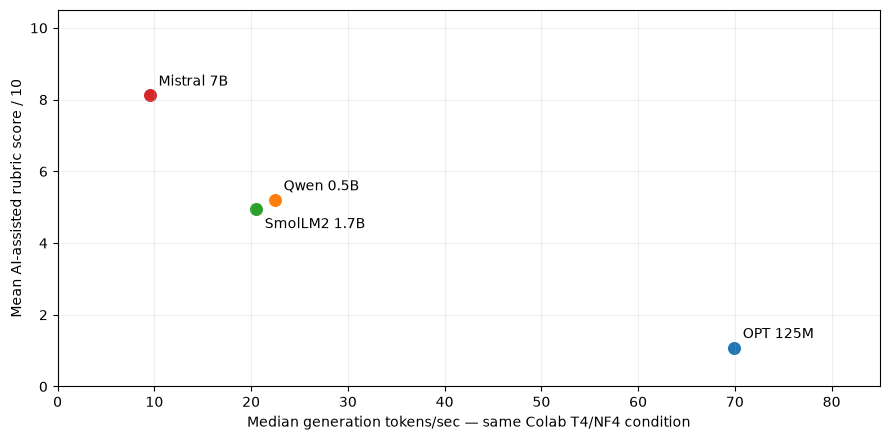

In [4]:
import matplotlib.pyplot as plt
figure_dir = ROOT/'a7/results/person2_figures'
figure_dir.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(9,4.5))
short_names = {'facebook/opt-125m':'OPT 125M', 'Qwen/Qwen2-0.5B-Instruct':'Qwen 0.5B',
 'HuggingFaceTB/SmolLM2-1.7B-Instruct':'SmolLM2 1.7B', 'mistralai/Mistral-7B-Instruct-v0.3':'Mistral 7B'}
for model, row in model_summary.iterrows():
    ax.scatter(row.median_tokens_per_second, row.mean_quality, s=70)
    ax.annotate(short_names[model], (row.median_tokens_per_second,row.mean_quality), xytext=(6,-14) if 'SmolLM2' in model else (6,7),textcoords='offset points')
ax.set(xlabel='Median generation tokens/sec — same Colab T4/NF4 condition',ylabel='Mean AI-assisted rubric score / 10',ylim=(0,10.5),xlim=(0,85))
ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(figure_dir/'benchmark_speed_quality.png', dpi=160)
plt.show()

## Workload and cloud configuration

Estimate **one request per DAU per day**, **256 input tokens and 500 generated tokens per request**. A multi-task request with several descriptions motivates the input/output budget; 500 outputs is the architecture lead's provisional planning assumption, **not a measurement from the 220-token-capped benchmarks**. This is a future workload scenario and extrapolates beyond observed generation lengths. Input/output token counts depend on tokenizer; these are common billing/planning units to align with Person 3, not a measured tokenizer-invariant count.

Use one published **Runpod RTX 3090 Pod**: 24 GB VRAM, 16 vCPUs, 125 GB host RAM, advertised **$0.50/hour**. Add 20 GB container disk plus 80 GB running volume at **$0.10/GB/month**, with an explicit 30-day month. Price check: **October 24, 2026**; page labeled updated October 8. The public listing does not specify a region or guarantee large-fleet availability. [Official GPU/storage prices](https://www.runpod.io/pricing), [billing documentation](https://docs.runpod.io/pods/pricing).

Per-machine compute = 24 × $0.50 = **$12/day**. Storage = 100 × $0.10 / 30 = **$0.333333/day**, so each provisioned machine costs **$12.333333/day** in this scope. These 90 rows are alternative single-model deployments, not a bill for serving all 15 simultaneously. Each replica holds one model. No VM has been purchased.

Scope: inference Pod compute, listed CPU/RAM, local disk and a thin co-hosted request handler. Shared Django/frontend/database costs are excluded equally from local/API alternatives. Egress, load balancing, backups, monitoring, labor, tax, redundancy and enterprise support are excluded; they must be added before production procurement. This is **inference-tier cost**, not complete application TCO. Person 3 must include the API tier's own required gateway compute/storage and use matching exclusion rules.

In [5]:
config = json.loads((ROOT/'a7/person2/cost_assumptions.json').read_text())
from a7.architecture_analysis import TRAFFIC
loads = pd.DataFrame([{'traffic_category':label,'daily_active_users':dau,
 'requests_per_user':config['requests_per_user'],
 'avg_output_tokens_per_user':config['requests_per_user']*config['output_tokens_per_request'],
 'daily_input_tokens':dau*config['requests_per_user']*config['input_tokens_per_request'],
 'daily_output_token_load':dau*config['requests_per_user']*config['output_tokens_per_request']}
 for label,dau in TRAFFIC.items()])
display(loads)
loads.to_csv(ROOT/'a7/results/person2_daily_token_loads.csv', index=False)
print('Assumptions ID:', config['assumptions_id'])

,traffic_category,daily_active_users,requests_per_user,avg_output_tokens_per_user,daily_input_tokens,daily_output_token_load
0,Prototype,1000,1,500,256000,500000
1,Early Startup,10000,1,500,2560000,5000000
2,Growing Product,100000,1,500,25600000,50000000
3,Large Platform,1000000,1,500,256000000,500000000
4,Mass Consumer App,10000000,1,500,2560000000,5000000000
5,Global Platform,100000000,1,500,25600000000,50000000000


Assumptions ID: hestia-a7-256in-500out-r1-inference-only-v1


## Capacity method: assumptions separated from measurements

For the four measured models, median T4 tokens/sec is the source anchor. The cloud target is a **different GPU (RTX 3090)**: a transfer multiplier of 1.0 is an explicit assumption, not a measured speed or a guaranteed conservative bound. For the other eleven models, use a disclosed log-linear interpolation in parameter count between these four anchors; below the smallest anchor use its rate, above the largest scale inversely with size. Architecture and tokenizer can dominate size, so these eleven estimates are weak and must not be reported as benchmark results.

Use peak/average demand **p=2**, target busy utilization **u=0.6**, and a **1.25× service-time penalty** for workload/prefill/request handling uncertainty. Benchmark `generate()` already includes its own prefill; this penalty is an additional planning allowance, not a separately measured prefill cost. Changing prompt lengths, concurrency and batching may change the rates substantially.

For daily output load L and planning rate t:

`effective tokens/sec = t × u / 1.25`

`machines = max(1, ceil(L × p / (86400 × effective tokens/sec)))`

`daily cost = machines × (24 × GPU hourly rate + per-machine disk monthly rate / 30)`

This sizes an always-on fleet for the assumed peak, not just GPU-hours at average load. It assumes load distributes perfectly and gives no queue-delay SLA; no standby or failover replica is included. Huge fleet counts at the upper traffic levels are scenario arithmetic, not available inventory or a feasible deployment plan.

Memory planning uses `2 × parameters_b + 8` decimal GB (FP16-sized weights plus runtime/KV headroom), one model/replica, compared with 24 GB VRAM. This is a coarse fit check despite the intended NF4 deployment, not measured peak allocation or proof that every model supports the same quantized loader. Validate the real model/runtime, KV cache, host loading peaks and concurrent serving before adopting these counts.

In [6]:
cost_rows, capacity_rows, sensitivity_rows = build_tables(config, raw.to_dict('records'))
costs = pd.DataFrame(cost_rows)
capacity = pd.DataFrame(capacity_rows)
sensitivity = pd.DataFrame(sensitivity_rows)
saved = pd.read_csv(ROOT/'a7/results/local_costs.csv', keep_default_na=False)
pd.testing.assert_frame_equal(saved, costs, check_dtype=False, rtol=1e-12)
assert len(costs)==90 and not costs.duplicated(['model_id','traffic_category']).any()
display(capacity.round(4))
print('4 measured T4 anchors; 11 size-only rate assumptions; all target-cloud capacities unvalidated.')

,model_id,params_b,planning_tokens_per_second,rate_basis,planning_memory_gb,memory_fit_assumed
0,distilbert/distilgpt2,0.082,69.9590,assumed_size_interpolation_T4_proxy_transferred_to_3090,8.164,True
1,facebook/opt-125m,0.125,69.9590,measured_T4_proxy_transferred_to_3090,8.250,True
2,HuggingFaceTB/SmolLM2-135M-Instruct,0.135,65.6526,assumed_size_interpolation_T4_proxy_transferred_to_3090,8.270,True
3,HuggingFaceTB/SmolLM-360M-Instruct,0.360,29.2151,assumed_size_interpolation_T4_proxy_transferred_to_3090,8.720,True
4,HuggingFaceTB/SmolLM2-360M-Instruct,0.360,29.2151,assumed_size_interpolation_T4_proxy_transferred_to_3090,8.720,True
5,Qwen/Qwen2-0.5B-Instruct,0.494,22.4989,measured_T4_proxy_transferred_to_3090,8.988,True
6,Qwen/Qwen3-0.6B,0.600,22.1787,assumed_size_interpolation_T4_proxy_transferred_to_3090,9.200,True
7,TinyLlama/TinyLlama-1.1B-Chat-v1.0,1.100,21.2093,assumed_size_interpolation_T4_proxy_transferred_to_3090,10.200,True
8,Qwen/Qwen2.5-1.5B-Instruct,1.540,20.6896,assumed_size_interpolation_T4_proxy_transferred_to_3090,11.080,True
9,HuggingFaceTB/SmolLM2-1.7B-Instruct,1.700,20.5394,measured_T4_proxy_transferred_to_3090,11.400,True


4 measured T4 anchors; 11 size-only rate assumptions; all target-cloud capacities unvalidated.


In [7]:
# Complete assignment table: 15 models × six traffic categories, with storage itemization.
display(costs[['model_id','traffic_category','avg_tokens_per_user','total_daily_token_load',
 'per_machine_compute_usd_day','per_machine_storage_usd_day','machines_needed',
 'total_machine_compute_usd_day','total_storage_usd_day','total_daily_cost_usd']])

,model_id,traffic_category,avg_tokens_per_user,total_daily_token_load,per_machine_compute_usd_day,per_machine_storage_usd_day,machines_needed,total_machine_compute_usd_day,total_storage_usd_day,total_daily_cost_usd
0,distilbert/distilgpt2,Prototype,500,500000,12.0,0.333333,1,12.0,0.333333,1.233333e+01
1,distilbert/distilgpt2,Early Startup,500,5000000,12.0,0.333333,4,48.0,1.333333,4.933333e+01
2,distilbert/distilgpt2,Growing Product,500,50000000,12.0,0.333333,35,420.0,11.666667,4.316667e+02
3,distilbert/distilgpt2,Large Platform,500,500000000,12.0,0.333333,345,4140.0,115.000000,4.255000e+03
4,distilbert/distilgpt2,Mass Consumer App,500,5000000000,12.0,0.333333,3447,41364.0,1149.000000,4.251300e+04
5,distilbert/distilgpt2,Global Platform,500,50000000000,12.0,0.333333,34467,413604.0,11489.000000,4.250930e+05
6,facebook/opt-125m,Prototype,500,500000,12.0,0.333333,1,12.0,0.333333,1.233333e+01
7,facebook/opt-125m,Early Startup,500,5000000,12.0,0.333333,4,48.0,1.333333,4.933333e+01
8,facebook/opt-125m,Growing Product,500,50000000,12.0,0.333333,35,420.0,11.666667,4.316667e+02
9,facebook/opt-125m,Large Platform,500,500000000,12.0,0.333333,345,4140.0,115.000000,4.255000e+03


,model_id,traffic_category,rate_factor,machines_needed,total_daily_cost_usd,scenario
168,HuggingFaceTB/SmolLM2-1.7B-Instruct,Growing Product,0.5,235,2898.333333,"assumed throughput sensitivity, not measured batching or hardware speedup"
169,HuggingFaceTB/SmolLM2-1.7B-Instruct,Growing Product,1.0,118,1455.333333,"assumed throughput sensitivity, not measured batching or hardware speedup"
170,HuggingFaceTB/SmolLM2-1.7B-Instruct,Growing Product,2.0,59,727.666667,"assumed throughput sensitivity, not measured batching or hardware speedup"
96,Qwen/Qwen2-0.5B-Instruct,Growing Product,0.5,215,2651.666667,"assumed throughput sensitivity, not measured batching or hardware speedup"
97,Qwen/Qwen2-0.5B-Instruct,Growing Product,1.0,108,1332.000000,"assumed throughput sensitivity, not measured batching or hardware speedup"
98,Qwen/Qwen2-0.5B-Instruct,Growing Product,2.0,54,666.000000,"assumed throughput sensitivity, not measured batching or hardware speedup"
24,facebook/opt-125m,Growing Product,0.5,69,851.000000,"assumed throughput sensitivity, not measured batching or hardware speedup"
25,facebook/opt-125m,Growing Product,1.0,35,431.666667,"assumed throughput sensitivity, not measured batching or hardware speedup"
26,facebook/opt-125m,Growing Product,2.0,18,222.000000,"assumed throughput sensitivity, not measured batching or hardware speedup"
240,mistralai/Mistral-7B-Instruct-v0.3,Growing Product,0.5,505,6228.333333,"assumed throughput sensitivity, not measured batching or hardware speedup"


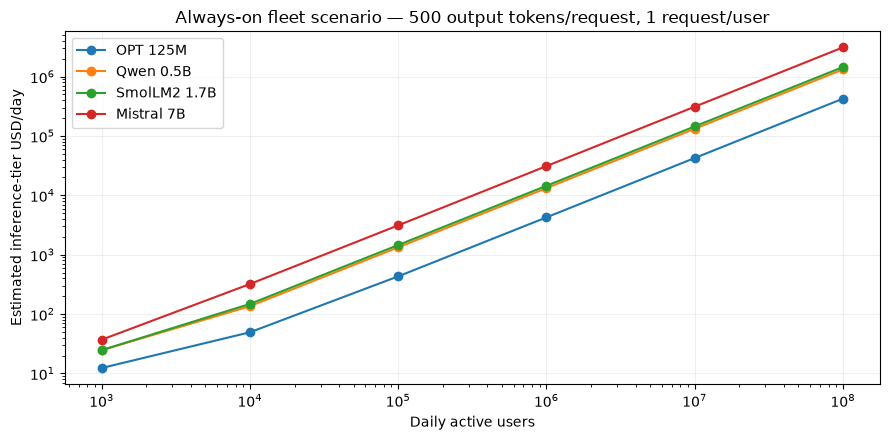

In [8]:
display(sensitivity[(sensitivity.traffic_category=='Growing Product') &
                       sensitivity.model_id.isin(short_names)].sort_values(['model_id','rate_factor']))
fig, ax = plt.subplots(figsize=(9,4.5))
for model,label in short_names.items():
    group = costs[costs.model_id==model].sort_values('daily_active_users')
    ax.plot(group.daily_active_users,group.total_daily_cost_usd,marker='o',label=label)
ax.set(xscale='log', yscale='log', xlabel='Daily active users',ylabel='Estimated inference-tier USD/day',
       title='Always-on fleet scenario — 500 output tokens/request, 1 request/user')
ax.grid(alpha=.2);ax.legend();fig.tight_layout()
fig.savefig(figure_dir/'local_cost_scaling.png', dpi=160)
plt.show()

## Interpretation and Person 3/4 handoff

For Mistral in this scenario, 1,000 DAU needs 3 machines ($37/day); 100,000 DAU needs 253 ($3,120.33/day); and 100 million DAU needs 252,019 ($3,108,234.33/day). This dramatic scaling follows the **unbatched proxy, 500-token output and peak/utilization assumptions**, not a demonstrated fleet requirement. Reducing output length, caching, batching, a faster GPU or API overflow may reduce costs, but their gains were not measured. Doubling/halving assumed throughput is shown in the 270-case sensitivity CSV, not claimed as a benchmark result.

A fast unhelpful model is not an acceptable cost optimization: OPT's low modeled cost does not overcome its 1.08/10 quality. Choose only models that pass task-specific quality and schema gates; these tests show validation/retry/fallback are needed. No 15-model fastest or quality winner is declared from four local-owner measurements.

Person 3 must use `hestia-a7-256in-500out-r1-inference-only-v1` with identical workload/cost boundaries, or both tables must be regenerated under an agreed replacement. There is **no supported local/API crossover conclusion yet** because the API table is absent. Person 4 can join `results/person2_benchmark.csv` and `results/local_costs.csv` using the existing interfaces; retain the raw evidence and precision labels.

Student review of the AI-assisted ratings remains required before final submission. The benchmarks are executed and the 90 local scenarios are calculated; assumptions have not been validated by production load tests.